In [19]:
import nltk

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [20]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
import pandas as pd
import numpy as np
import re
import string
from collections import Counter

import matplotlib.pyplot as plt
import seaborn as sns

## Load the dataset

In [22]:
df = pd.read_excel('/content/drive/MyDrive/Colab Notebooks/dataset.xlsx')
df.head()

,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."


## Basic structural overview

In [23]:
print("Shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe(include='all').T

Shape: (1440, 3)

Column names: ['title', 'rating', 'body']

Data types:
 title     object
rating     int64
body      object
dtype: object

Missing values:
 title     0
rating    0
body      0
dtype: int64

Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
title,1440,1351,Value for money,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,1440.0,NaN,NaN,NaN,3.173611,1.584453,1.0,1.0,4.0,5.0,5.0
body,1440,1440,Good phone for budget buyers. Sound quality is...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Target variable: rating distribution

rating
1    26.8%
2     8.8%
3    13.8%
4    21.5%
5    29.1%
Name: proportion, dtype: object


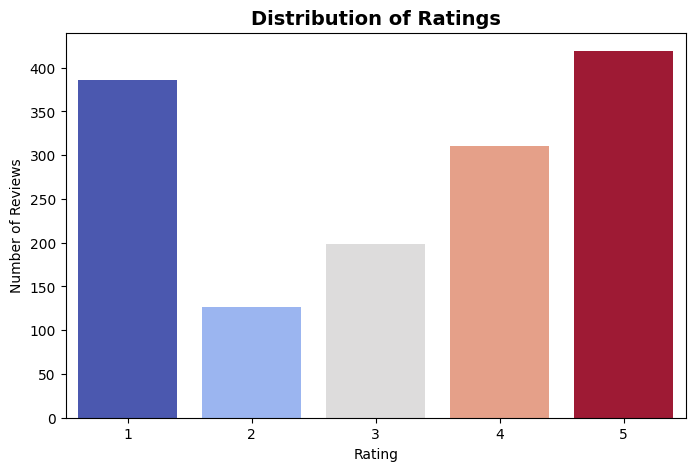

In [24]:
plt.figure(figsize=(8, 5))
order = sorted(df['rating'].unique())
ax = sns.countplot(x='rating', hue='rating', data=df, palette='coolwarm',
                    order=order, legend=False)
plt.title('Distribution of Ratings', fontsize=14, fontweight='bold')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')
# Formats directly as percentages (e.g., 31.5%)
print(df['rating'].value_counts(normalize=True).sort_index().apply(lambda x: f"{x:.1%}"))

## Text length analysis

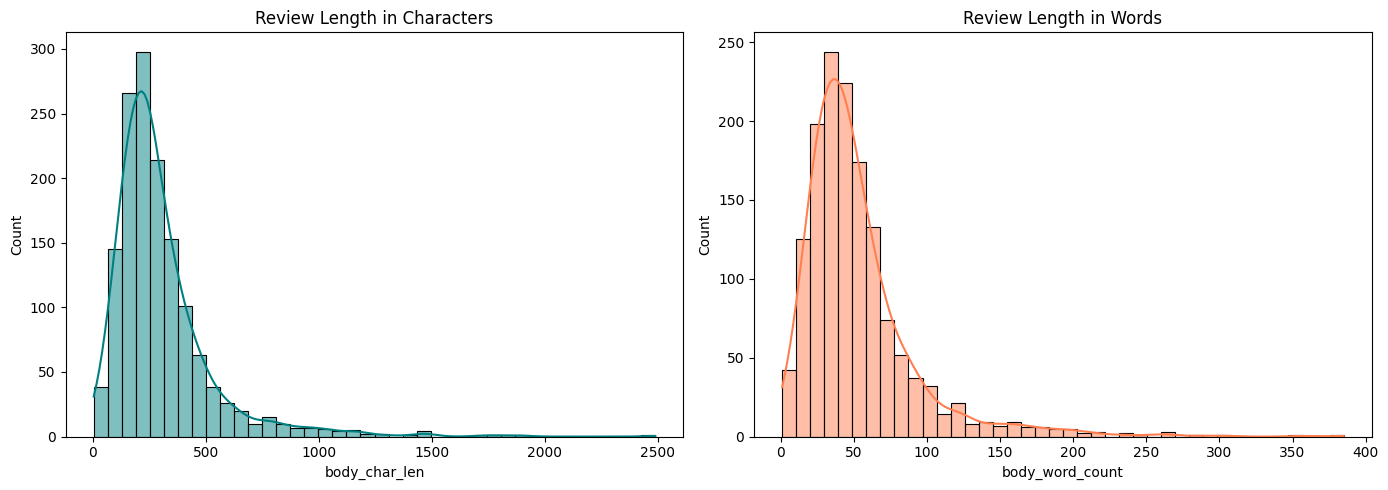

In [25]:
df['title_char_len']  = df['title'].astype(str).apply(len)
df['body_char_len']   = df['body'].astype(str).apply(len)
df['body_word_count'] = df['body'].astype(str).apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['body_char_len'], bins=40, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Review Length in Characters')
sns.histplot(df['body_word_count'], bins=40, kde=True, ax=axes[1], color='coral')
axes[1].set_title('Review Length in Words')
plt.tight_layout()
plt.show()


## Text cleaning

In [26]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk import pos_tag


lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))


def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)               # URLs
    text = re.sub(r'<.*?>', ' ', text)                         # HTML tags
    text = re.sub(r'[^\x00-\x7F]+', ' ', text)                 # emojis / non-English scripts
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\d+', ' ', text)                           # numbers
    text = re.sub(r'\s+', ' ', text).strip()

    tokens = word_tokenize(text)
    tokens = [w for w in tokens if w not in stop_words and len(w) > 2]
    tokens = [lemmatizer.lemmatize(w) for w in tokens]
    return ' '.join(tokens)

df['clean_body'] = df['body'].apply(clean_text)

# A few reviews are written almost entirely in Hindi script — after stripping
# non-ASCII characters they end up empty, so drop those:
df = df[df['clean_body'].str.len() > 0].reset_index(drop=True)
print("Shape after cleaning:", df.shape)

df[['body', 'clean_body']].head(10)

Shape after cleaning: (1436, 7)


,body,clean_body
0,Very disappointed with the overall performance...,disappointed overall performance samsung
1,Camera quality is low,camera quality low
2,"Got the mobile on the launch date,Battery must...",got mobile launch datebattery must appreciated...
3,1. It doesn't work with 5.0GHz WiFi frequency....,doesnt work ghz wifi frequency ghz old school ...
4,"Not worth buying....faulty software, poor disp...",worth buyingfaulty software poor display quali...
5,I will never purchase Samsung phones. Phone is...,never purchase samsung phone phone lagging muc...
6,This is worst samsung mobile I have seen from ...,worst samsung mobile seen samsung sceen qualit...
7,The phone hangs a lot and is very slow. I rece...,phone hang lot slow received replacement conti...
8,Very poor quality camera .Found box seal damag...,poor quality camera found box seal damage stil...
9,Worst camera quality. It is like 2 megapixel c...,worst camera quality like megapixel camera pho...


Vocabulary size: 6002


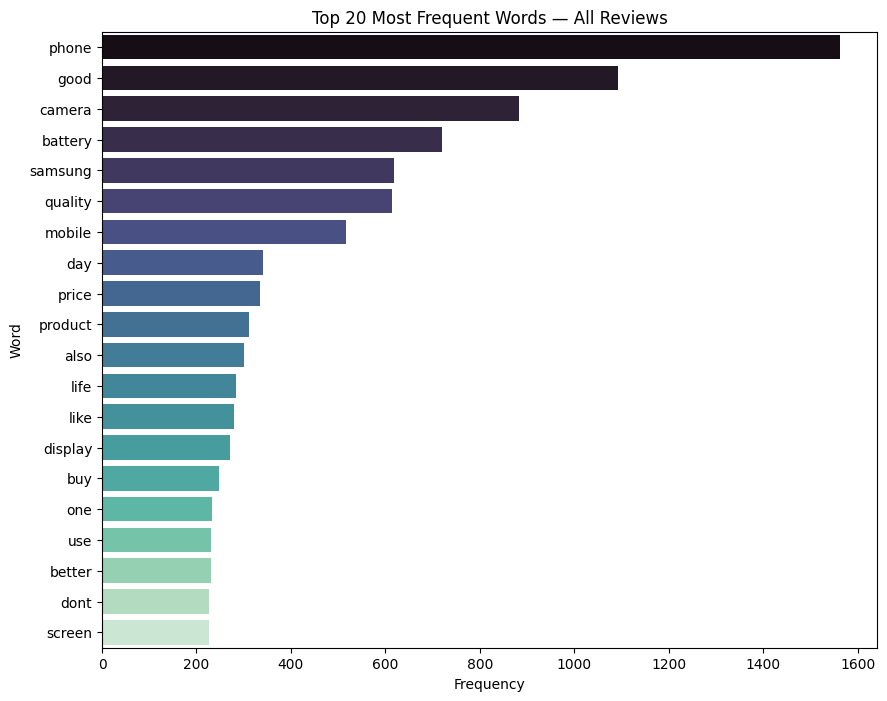

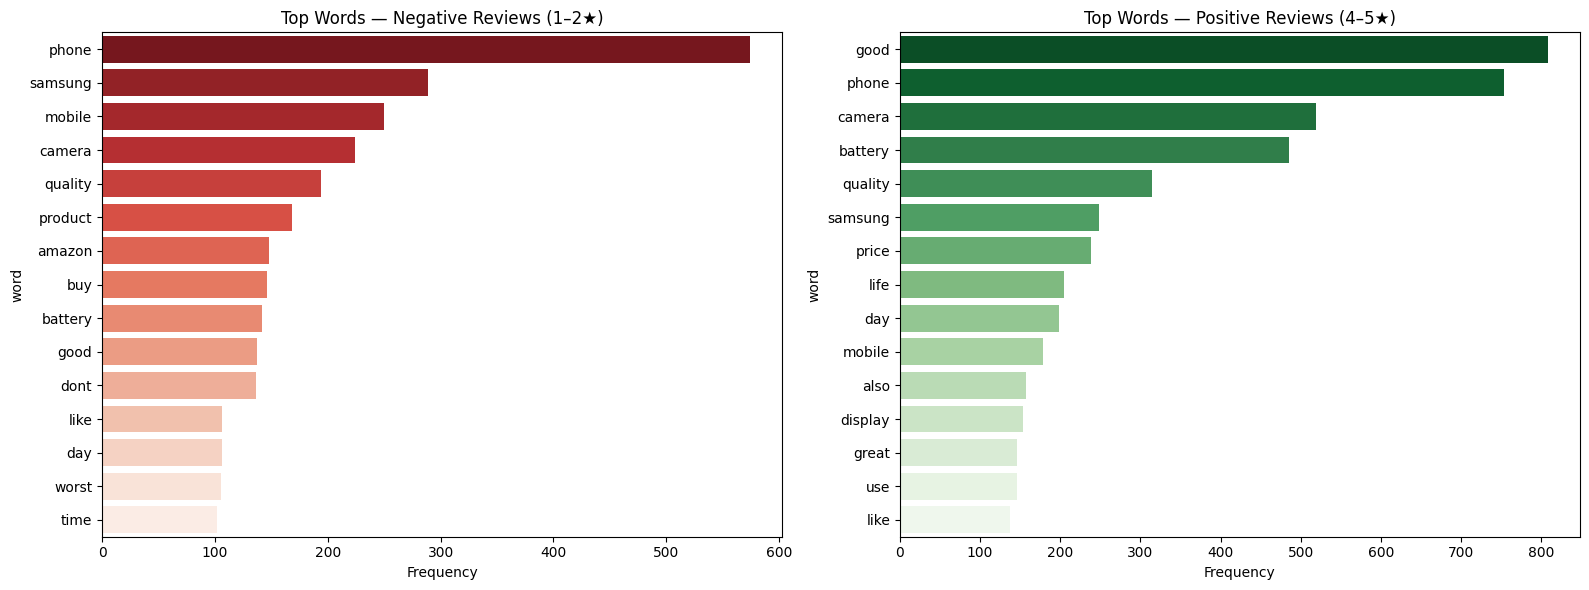

In [27]:


# 1. Overall Top 20 Most Frequent Words
all_words = ' '.join(df['clean_body']).split()
word_freq = Counter(all_words)
print("Vocabulary size:", len(word_freq))

# Convert top 20 to DataFrame for cleaner Seaborn plotting
top20_df = pd.DataFrame(word_freq.most_common(20), columns=['word', 'count'])

plt.figure(figsize=(10, 8))
sns.barplot(data=top20_df, x='count', y='word', hue='word', palette='mako', legend=False)
plt.title('Top 20 Most Frequent Words — All Reviews')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.show()

# 2. Top 15 Words for Negative vs Positive Reviews (Inline without def)
neg_text = ' '.join(df[df['rating'].isin([1, 2])]['clean_body'])
pos_text = ' '.join(df[df['rating'].isin([4, 5])]['clean_body'])

neg_df = pd.DataFrame(Counter(neg_text.split()).most_common(15), columns=['word', 'count'])
pos_df = pd.DataFrame(Counter(pos_text.split()).most_common(15), columns=['word', 'count'])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=neg_df, x='count', y='word', hue='word', ax=axes[0], palette='Reds_r', legend=False)
axes[0].set_title('Top Words — Negative Reviews (1–2★)')
axes[0].set_xlabel('Frequency')

sns.barplot(data=pos_df, x='count', y='word', hue='word', ax=axes[1], palette='Greens_r', legend=False)
axes[1].set_title('Top Words — Positive Reviews (4–5★)')
axes[1].set_xlabel('Frequency')

plt.tight_layout()
plt.show()

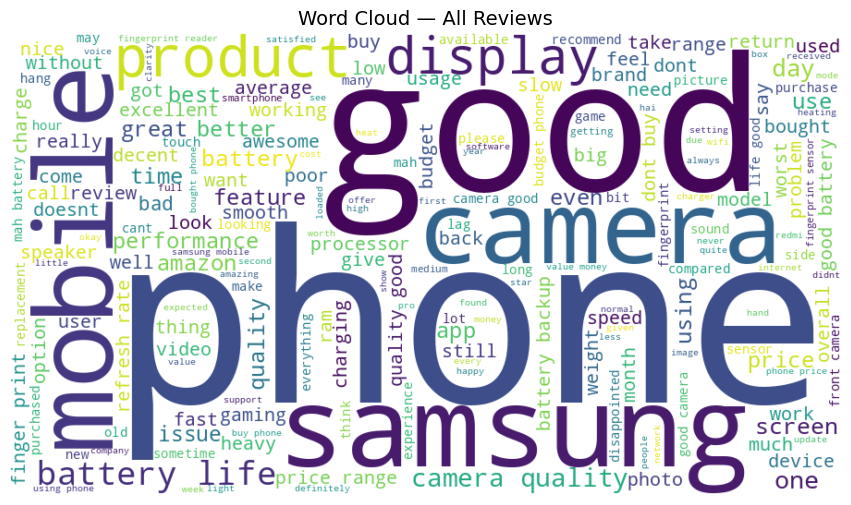

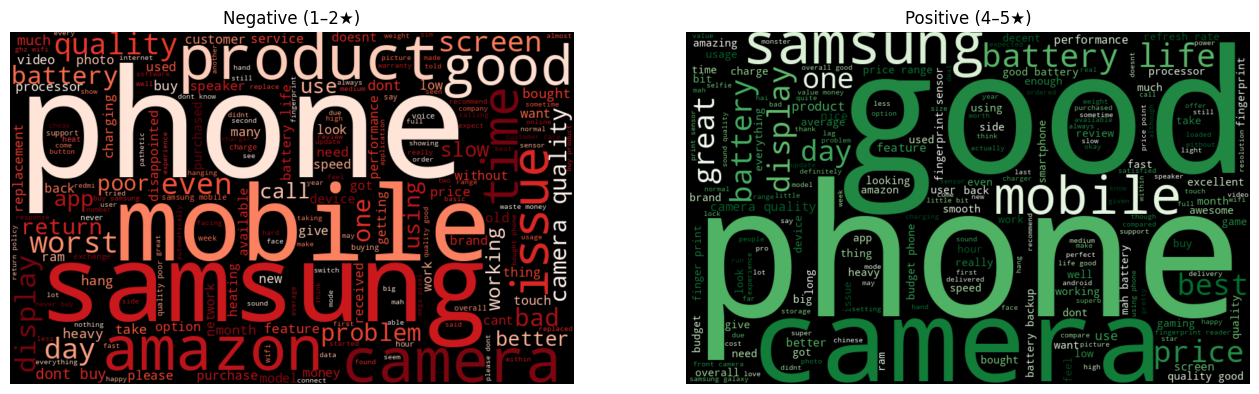

In [28]:
from wordcloud import WordCloud

wc_all = WordCloud(width=900, height=500, background_color='white',
                    colormap='viridis').generate(' '.join(df['clean_body']))
plt.figure(figsize=(12, 6))
plt.imshow(wc_all, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud — All Reviews', fontsize=14)
plt.show()

neg_text = ' '.join(df[df['rating'] <= 2]['clean_body'])
pos_text = ' '.join(df[df['rating'] >= 4]['clean_body'])
wc_neg = WordCloud(width=800, height=500, background_color='black', colormap='Reds').generate(neg_text)
wc_pos = WordCloud(width=800, height=500, background_color='black', colormap='Greens').generate(pos_text)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].imshow(wc_neg, interpolation='bilinear'); axes[0].axis('off'); axes[0].set_title('Negative (1–2★)')
axes[1].imshow(wc_pos, interpolation='bilinear'); axes[1].axis('off'); axes[1].set_title('Positive (4–5★)')
plt.show()

In [29]:
df

,title,rating,body,title_char_len,body_char_len,body_word_count,clean_body
0,Horrible product,1,Very disappointed with the overall performance...,16,59,8,disappointed overall performance samsung
1,Camera quality is not like 48 megapixel,3,Camera quality is low,39,21,4,camera quality low
2,Overall,4,"Got the mobile on the launch date,Battery must...",7,403,66,got mobile launch datebattery must appreciated...
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....,16,377,67,doesnt work ghz wifi frequency ghz old school ...
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp...",29,179,29,worth buyingfaulty software poor display quali...
...,...,...,...,...,...,...,...
1431,Excellent mobile,5,Excellent mobile,16,16,2,excellent mobile
1432,Never expected from samsung,1,"All over mobile performance is very poor, neve...",27,188,31,mobile performance poor never buy one product ...
1433,Good value for money,5,Battery life is good but camera clarity could ...,20,98,17,battery life good camera clarity could little ...
1434,Unreal and whitish display,1,"It's a very bad product, highly dissatisfied.....",26,207,35,bad product highly dissatisfied specifically c...


## Model Building And Evaluation

In [30]:
# Create Sentiment Categories

def get_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

df["sentiment"] = df["rating"].apply(get_sentiment)

print(df["sentiment"].value_counts())

sentiment
Positive    729
Negative    508
Neutral     199
Name: count, dtype: int64


In [31]:
# Train-Test Split

from sklearn.model_selection import train_test_split

X_text = df["clean_body"]
y = df["sentiment"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train_text.shape)
print("Testing Data:", X_test_text.shape)

Training Data: (1148,)
Testing Data: (288,)


In [32]:
# TF-IDF Feature Extraction

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

Training Features: (1148, 5000)
Testing Features: (288, 5000)


## Models For Training Testing

In [33]:
# Import Models

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

In [34]:
# Logistic Regression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

In [35]:
# Logistic Regression Evaluation

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_pred))

print("\nClassification Report:")
print(classification_report(y_test, lr_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

Logistic Regression Accuracy: 0.7430555555555556

Classification Report:
              precision    recall  f1-score   support

    Negative       0.75      0.76      0.76       102
     Neutral       0.50      0.03      0.05        40
    Positive       0.74      0.92      0.82       146

    accuracy                           0.74       288
   macro avg       0.66      0.57      0.54       288
weighted avg       0.71      0.74      0.69       288


Confusion Matrix:
[[ 78   1  23]
 [ 15   1  24]
 [ 11   0 135]]


In [36]:
# Random Forest

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [37]:
# Random Forest Evaluation

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest Accuracy: 0.7222222222222222

Classification Report:
              precision    recall  f1-score   support

    Negative       0.77      0.69      0.73       102
     Neutral       0.00      0.00      0.00        40
    Positive       0.70      0.95      0.80       146

    accuracy                           0.72       288
   macro avg       0.49      0.54      0.51       288
weighted avg       0.63      0.72      0.66       288


Confusion Matrix:
[[ 70   0  32]
 [ 13   0  27]
 [  8   0 138]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [38]:
# Linear SVM

svm_model = LinearSVC()

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

In [39]:
# Linear SVM Evaluation

print("Linear SVM Accuracy:",
      accuracy_score(y_test, svm_pred))

print("\nClassification Report:")
print(classification_report(y_test, svm_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_pred))

Linear SVM Accuracy: 0.7569444444444444

Classification Report:
              precision    recall  f1-score   support

    Negative       0.72      0.79      0.75       102
     Neutral       0.57      0.20      0.30        40
    Positive       0.80      0.88      0.84       146

    accuracy                           0.76       288
   macro avg       0.70      0.63      0.63       288
weighted avg       0.74      0.76      0.73       288


Confusion Matrix:
[[ 81   4  17]
 [ 17   8  15]
 [ 15   2 129]]


In [40]:
# Model Comparison

from sklearn.metrics import precision_score, recall_score, f1_score

results = {
    "Logistic Regression": [
        accuracy_score(y_test, lr_pred),
        precision_score(y_test, lr_pred, average="weighted"),
        recall_score(y_test, lr_pred, average="weighted"),
        f1_score(y_test, lr_pred, average="weighted")
    ],

    "Random Forest": [
        accuracy_score(y_test, rf_pred),
        precision_score(y_test, rf_pred, average="weighted"),
        recall_score(y_test, rf_pred, average="weighted"),
        f1_score(y_test, rf_pred, average="weighted")
    ],

    "Linear SVM": [
        accuracy_score(y_test, svm_pred),
        precision_score(y_test, svm_pred, average="weighted"),
        recall_score(y_test, svm_pred, average="weighted"),
        f1_score(y_test, svm_pred, average="weighted")
    ]
}

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [41]:
# Create Comparison Table

import pandas as pd

comparison = pd.DataFrame(
    results,
    index=["Accuracy", "Precision", "Recall", "F1 Score"]
).T

comparison

,Accuracy,Precision,Recall,F1 Score
Logistic Regression,0.743056,0.711100,0.743056,0.692119
Random Forest,0.722222,0.627554,0.722222,0.664829
Linear SVM,0.756944,0.739422,0.756944,0.734044


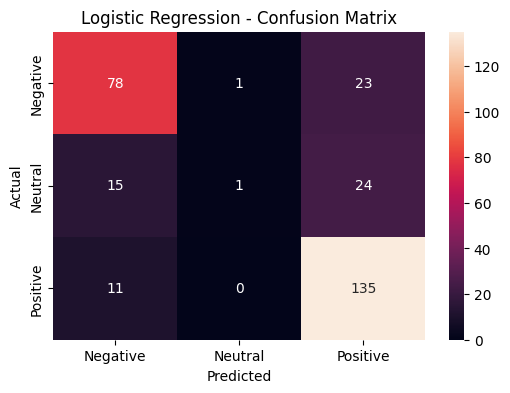

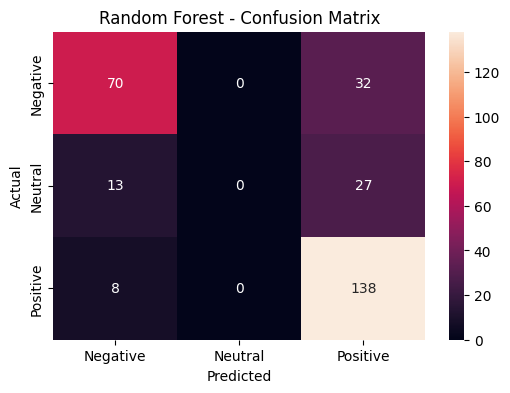

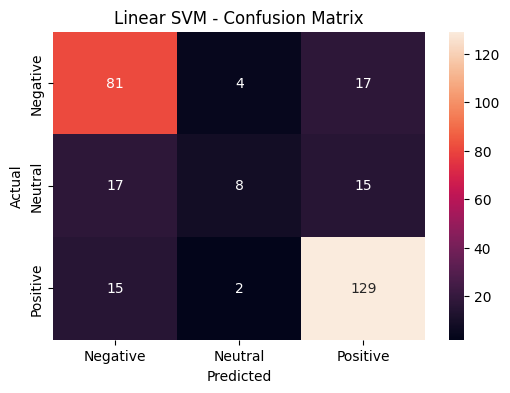

In [42]:
# Confusion Matrices

import matplotlib.pyplot as plt
import seaborn as sns

models = {
    "Logistic Regression": lr_pred,
    "Random Forest": rf_pred,
    "Linear SVM": svm_pred
}

for name, predictions in models.items():
    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=["Negative", "Neutral", "Positive"],
        yticklabels=["Negative", "Neutral", "Positive"]
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [43]:
# Select Best Model

best_model_name = comparison["F1 Score"].idxmax()

print("Best Model:", best_model_name)
print("Best F1 Score:", comparison.loc[best_model_name, "F1 Score"])

Best Model: Linear SVM
Best F1 Score: 0.7340442160043368


In [44]:
# Get Best Model

if best_model_name == "Logistic Regression":
    best_model = lr_model

elif best_model_name == "Random Forest":
    best_model = rf_model

else:
    best_model = svm_model

print("Selected Model:", best_model_name)

Selected Model: Linear SVM


In [45]:
# Save Model and TF-IDF Vectorizer

import joblib

joblib.dump(best_model, "sentiment_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and TF-IDF vectorizer saved successfully.")

Model and TF-IDF vectorizer saved successfully.


In [46]:
# Test Saved Model

loaded_model = joblib.load("sentiment_model.pkl")
loaded_tfidf = joblib.load("tfidf_vectorizer.pkl")

sample_review = ["This product is amazing and I really love it"]

sample_features = loaded_tfidf.transform(sample_review)

prediction = loaded_model.predict(sample_features)

print("Predicted Sentiment:", prediction[0])

Predicted Sentiment: Positive


In [47]:
%%writefile app.py

import streamlit as st
import joblib
import re
import string

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer


# Download required NLTK resources
nltk.download("stopwords", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("wordnet", quiet=True)


# Load Model and TF-IDF
model = joblib.load("sentiment_model.pkl")
tfidf = joblib.load("tfidf_vectorizer.pkl")


# Text Cleaning
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))


def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^\x00-\x7F]+", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = word_tokenize(text)
    tokens = [w for w in tokens if w not in stop_words and len(w) > 2]
    tokens = [lemmatizer.lemmatize(w) for w in tokens]

    return " ".join(tokens)


# Streamlit App
st.title("Customer Review Sentiment Analysis")

st.write("Enter a customer review to predict its sentiment.")


review = st.text_area("Enter your review:")


if st.button("Predict Sentiment"):

    if review.strip() == "":
        st.warning("Please enter a review.")

    else:
        cleaned_review = clean_text(review)

        features = tfidf.transform([cleaned_review])

        prediction = model.predict(features)[0]

        st.success(f"Predicted Sentiment: {prediction}")

Writing app.py


In [48]:
%%writefile requirements.txt

streamlit
scikit-learn
joblib
nltk

Writing requirements.txt
